# El Niño — data prep for the D3 vis (DSC 106 Project 3)

**Dataset:** CMIP6 `amip` experiment, NCAR **CESM2**, member `r1i1p1f1` (Google Cloud public bucket `gs://cmip6`).
AMIP runs use **observed** sea surface temperatures, so real El Niño events appear in the right years;
precipitation is the model's **simulated** response to those ocean temperatures.

**What this notebook does**
1. Opens `Amon/ts`, `Amon/pr`, `fx/sftlf` straight from Google Cloud (nothing to download by hand)
2. Computes monthly anomalies and the Niño 3.4 index / ONI with El Niño / La Niña labels
3. Makes 6 static exploratory plots (for the checkpoint video)
4. Exports small static files into `data/` for the D3 site

**Run locally:** open this notebook in VS Code from the repo's `notebooks/` folder, pick the `elnino` kernel, and Run All.
Output goes straight into the repo's `data/` folder (~15 MB). Takes a few minutes, mostly downloading.
**Or in Colab:** upload it and Run All; the last cell zips `data/` for download.

## 1. Setup

In [1]:
# Only needed in Colab, or if you didn't create the env from environment.yml
#%pip install -q xarray zarr gcsfs dask cftime matplotlib pandas

In [2]:
import json, os, shutil, sys
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

MODEL  = "CESM2"
MEMBER = "r1i1p1f1"
BASE   = slice("1981-01-01", "2010-12-31")   # climatology base period for anomalies
IN_COLAB = "google.colab" in sys.modules
OUT    = "data" if IN_COLAB else "../data"     # locally: repo/data (notebook lives in repo/notebooks)
os.makedirs(OUT, exist_ok=True)

## 2. Open the data from Google Cloud

Looks up each variable in the Pangeo CMIP6 catalog and opens the Zarr store lazily.
The printed `gs://...` paths match the folders you see in the Cloud console.

In [3]:
cat = pd.read_csv("https://storage.googleapis.com/cmip6/pangeo-cmip6.csv")

def open_var(variable, table="Amon"):
    rows = cat.query(
        "source_id == @MODEL and experiment_id == 'amip' and member_id == @MEMBER "
        "and table_id == @table and variable_id == @variable"
    )
    if rows.empty:
        raise ValueError(f"{MODEL} amip {MEMBER} {table}/{variable} not in catalog")
    path = rows.sort_values("version").iloc[-1].zstore
    print(path)
    ds = xr.open_zarr(path, consolidated=True, storage_options={"token": "anon"})
    return ds[variable]

ts    = open_var("ts").load()                        # surface temperature, K
pr    = open_var("pr").load()                        # precipitation, kg m-2 s-1
sftlf = open_var("sftlf", table="fx").load()         # % of each cell that is land

gs://cmip6/CMIP6/CMIP/NCAR/CESM2/amip/r1i1p1f1/Amon/ts/gn/v20190218/


/Users/justinjames/miniforge3/envs/elnino/lib/python3.12/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.82.2. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(
/Users/justinjames/miniforge3/envs/elnino/lib/python3.12/site-packages/google/auth/transport/grpc.py:43: FutureWarning: grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, google-auth will raise its minimum requirements to enforce grpcio >= 1.83.0. For more details

gs://cmip6/CMIP6/CMIP/NCAR/CESM2/amip/r1i1p1f1/Amon/pr/gn/v20190319/
gs://cmip6/CMIP6/CMIP/NCAR/CESM2/amip/r1i1p1f1/fx/sftlf/gn/v20190218/


In [4]:
# Units + land/ocean mask
ts_c = ts - 273.15                 # K -> °C
pr   = pr * 86400                  # kg m-2 s-1 -> mm/day
assert sftlf.shape == ts.isel(time=0).shape, "land mask grid doesn't match"
sftlf = sftlf.assign_coords(lat=ts.lat, lon=ts.lon)   # guard against float mismatches
pr    = pr.assign_coords(lat=ts.lat, lon=ts.lon)
ocean = sftlf < 50
sst = ts_c.where(ocean)            # over ocean, AMIP ts = observed SST

t = ts.time.values
print(f"time: {t[0].year}-{t[0].month:02d} to {t[-1].year}-{t[-1].month:02d}  ({ts.sizes['time']} months)")
print(f"grid: {ts.sizes['lat']} lat x {ts.sizes['lon']} lon, lon range {float(ts.lon.min())}–{float(ts.lon.max())}")

time: 1950-01 to 2014-12  (780 months)
grid: 192 lat x 288 lon, lon range 0.0–358.75


## 3. Anomalies and the Niño 3.4 index

* **Anomaly** = value minus the average for that calendar month over the 1981–2010 base period.
* **Niño 3.4** = area-weighted mean SST anomaly over 5°S–5°N, 170°W–120°W (= 190–240 °E on this 0–360 grid).
* **ONI** = 3-month running mean of Niño 3.4. El Niño (La Niña) = ONI ≥ +0.5 °C (≤ −0.5 °C) for at least 5 months in a row, following NOAA's definition.

In [5]:
def anomalies(da):
    clim = da.sel(time=BASE).groupby("time.month").mean("time")
    return (da.groupby("time.month") - clim).drop_vars("month")

sst_anom = anomalies(sst)
pr_anom  = anomalies(pr)

def box_mean(da, lat0, lat1, lon0, lon1):
    box = da.sel(lat=slice(lat0, lat1), lon=slice(lon0, lon1))
    return box.weighted(np.cos(np.deg2rad(box.lat))).mean(("lat", "lon"))

nino34 = box_mean(sst_anom, -5, 5, 190, 240)
oni    = nino34.rolling(time=3, center=True).mean()

def label_phase(values, thresh=0.5, min_len=5):
    s = pd.Series(values)
    phase = pd.Series("Neutral", index=s.index)
    for sign, name in [(1, "El Niño"), (-1, "La Niña")]:
        hit = (sign * s) >= thresh
        run_id = (hit != hit.shift()).cumsum()
        run_len = hit.groupby(run_id).transform("sum")
        phase[hit & (run_len >= min_len)] = name
    return phase

years  = np.array([d.year for d in nino34.time.values])
months = np.array([d.month for d in nino34.time.values])
idx = pd.DataFrame({
    "date":   [f"{y}-{m:02d}" for y, m in zip(years, months)],
    "year":   years,
    "month":  months,
    "nino34": nino34.values.round(2),
    "oni":    oni.values.round(2),
})
idx["phase"] = label_phase(idx["oni"].values)
idx.to_csv(f"{OUT}/nino34.csv", index=False)

# Strongest events (peak ONI) — handy for annotations in the vis
idx["event"] = (idx.phase != idx.phase.shift()).cumsum()
events = (idx[idx.phase != "Neutral"].groupby("event")
          .agg(phase=("phase", "first"), start=("date", "first"), end=("date", "last"),
               peak=("oni", lambda x: x.loc[x.abs().idxmax()])))
events.to_csv(f"{OUT}/events.csv", index=False)
events.sort_values("peak", key=abs, ascending=False).head(10)

,phase,start,end,peak
event,,,,
48,El Niño,1997-05,1998-04,2.67
32,El Niño,1982-05,1983-05,2.65
40,La Niña,1988-04,1989-07,-2.26
24,La Niña,1973-05,1974-07,-2.14
22,El Niño,1972-06,1973-03,1.93
42,El Niño,1991-06,1992-06,1.87
60,La Niña,2007-08,2008-05,-1.80
6,La Niña,1954-05,1957-01,-1.75
50,La Niña,1998-06,2000-07,-1.72


## 4. Exploratory plots (checkpoint video)

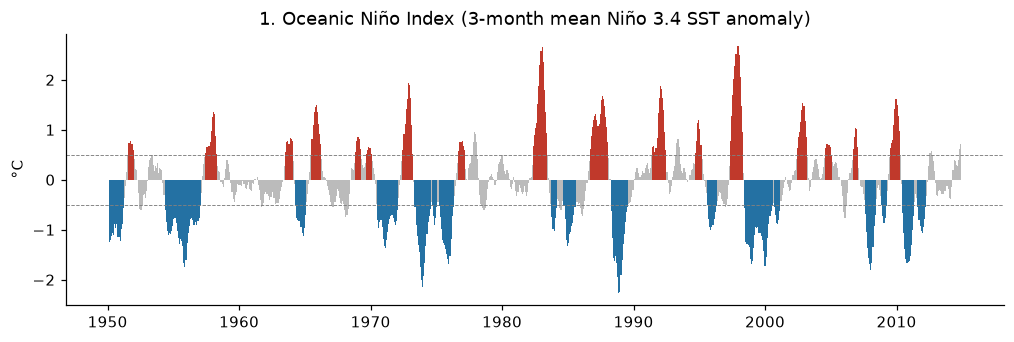

In [6]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
lon, lat = sst_anom.lon.values, sst_anom.lat.values
def coast(ax):
    ax.contour(lon, lat, sftlf.values, levels=[50], colors="k", linewidths=0.4)

def pick(da, year, month):
    sel = (years == year) & (months == month)
    return da.isel(time=np.where(sel)[0][0])

# Plot 1 — ONI timeline
colors = np.where(idx.phase == "El Niño", "#c0392b", np.where(idx.phase == "La Niña", "#2471a3", "#bbbbbb"))
x = idx.year + (idx.month - 0.5) / 12
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(x, idx.oni, width=1/12, color=colors)
for y in (0.5, -0.5):
    ax.axhline(y, color="gray", lw=0.6, ls="--")
ax.set(title="1. Oceanic Niño Index (3-month mean Niño 3.4 SST anomaly)", ylabel="°C")
plt.show()

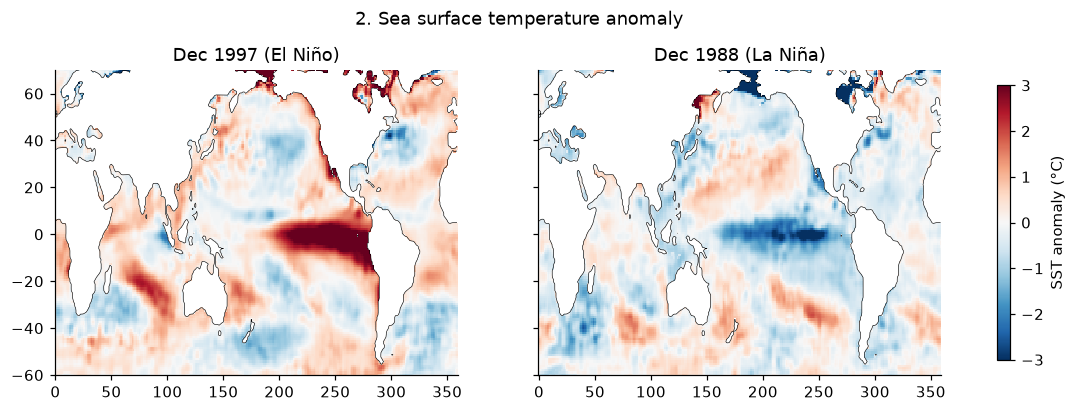

In [7]:
# Plot 2 — SST anomaly maps: El Niño peak vs La Niña peak
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, (y, m, label) in zip(axes, [(1997, 12, "Dec 1997 (El Niño)"), (1988, 12, "Dec 1988 (La Niña)")]):
    im = ax.pcolormesh(lon, lat, pick(sst_anom, y, m), cmap="RdBu_r", vmin=-3, vmax=3, shading="auto")
    coast(ax); ax.set(title=label, ylim=(-60, 70))
fig.colorbar(im, ax=axes, label="SST anomaly (°C)", shrink=0.9)
fig.suptitle("2. Sea surface temperature anomaly", x=0.45, y=1.03)
plt.show()

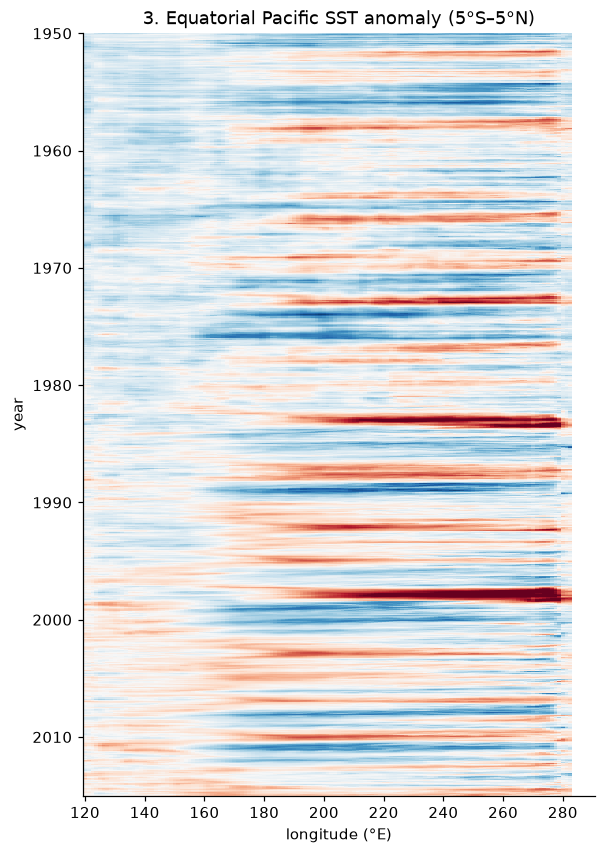

In [8]:
# Plot 3 — Hovmöller: equatorial SST anomaly, longitude vs time
eq = sst_anom.sel(lat=slice(-5, 5), lon=slice(120, 290))
eq = eq.weighted(np.cos(np.deg2rad(eq.lat))).mean("lat")
fig, ax = plt.subplots(figsize=(6, 9))
ax.pcolormesh(eq.lon, years + (months - 0.5) / 12, eq.values, cmap="RdBu_r", vmin=-3, vmax=3, shading="auto")
ax.invert_yaxis()
ax.set(title="3. Equatorial Pacific SST anomaly (5°S–5°N)", xlabel="longitude (°E)", ylabel="year")
plt.show()

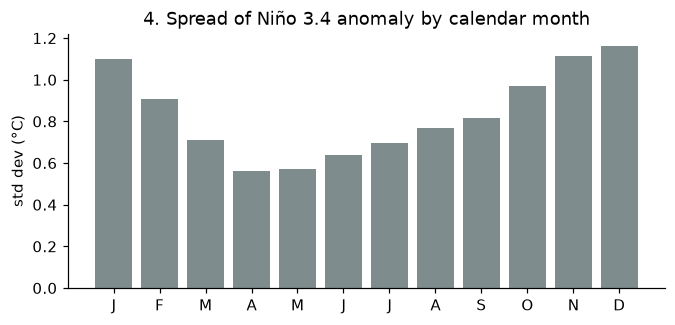

In [9]:
# Plot 4 — When in the year do events peak?
by_month = idx.groupby("month").nino34.std()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(by_month.index, by_month.values, color="#7f8c8d")
ax.set(xticks=range(1, 13), xticklabels=list("JFMAMJJASOND"),
       title="4. Spread of Niño 3.4 anomaly by calendar month", ylabel="std dev (°C)")
plt.show()

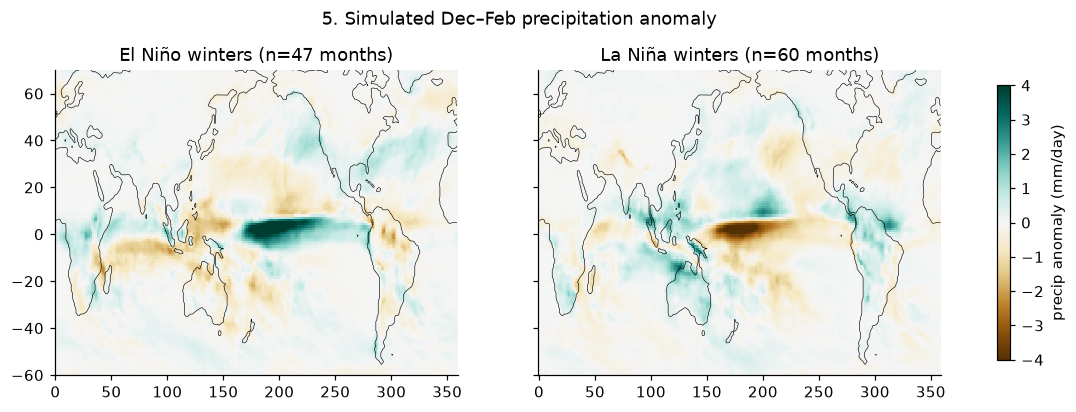

In [10]:
# Plot 5 — Winter (Dec–Feb) rainfall anomaly composite during El Niño
djf = np.isin(months, [12, 1, 2])
nino_djf = djf & (idx.phase.values == "El Niño")
nina_djf = djf & (idx.phase.values == "La Niña")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, mask, label in [(axes[0], nino_djf, "El Niño winters"), (axes[1], nina_djf, "La Niña winters")]:
    comp = pr_anom.isel(time=np.where(mask)[0]).mean("time")
    im = ax.pcolormesh(lon, lat, comp, cmap="BrBG", vmin=-4, vmax=4, shading="auto")
    coast(ax); ax.set(title=f"{label} (n={mask.sum()} months)", ylim=(-60, 70))
fig.colorbar(im, ax=axes, label="precip anomaly (mm/day)", shrink=0.9)
fig.suptitle("5. Simulated Dec–Feb precipitation anomaly", x=0.45, y=1.03)
plt.show()

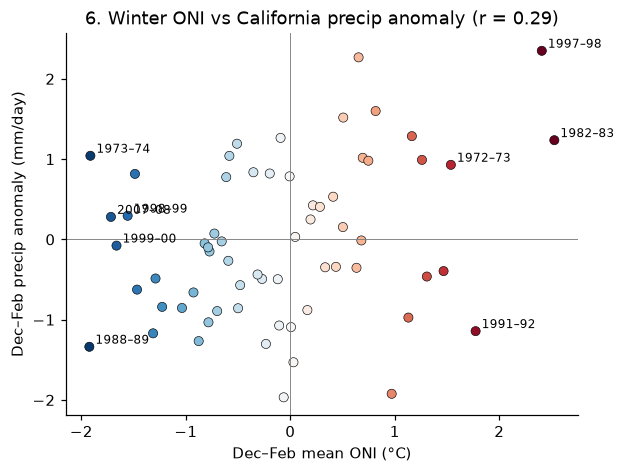

In [11]:
# Plot 6 — Does El Niño make California winters wetter? (land cells, 32–42°N, 124–114°W)
ca = box_mean(pr_anom.where(~ocean), 32, 42, 236, 246)
g = pd.DataFrame({"winter": years + (months == 12), "oni": idx.oni.values, "ca": ca.values})[djf].groupby("winter")
win = g.mean()[g.size() == 3].dropna()          # keep only complete Dec–Jan–Feb winters
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(win.oni, win.ca, c=win.oni, cmap="RdBu_r", vmin=-2, vmax=2, edgecolor="k", lw=0.4)
for yr, r in win[win.oni.abs() > 1.5].iterrows():
    ax.annotate(f"{yr-1}–{str(yr)[2:]}", (r.oni, r.ca), fontsize=8, xytext=(4, 2), textcoords="offset points")
r = np.corrcoef(win.oni, win.ca)[0, 1]
ax.axhline(0, color="gray", lw=0.6); ax.axvline(0, color="gray", lw=0.6)
ax.set(title=f"6. Winter ONI vs California precip anomaly (r = {r:.2f})",
       xlabel="Dec–Feb mean ONI (°C)", ylabel="Dec–Feb precip anomaly (mm/day)")
plt.show()

## 5. Export for D3

Coarsened 4×4 (CESM2's ~1° grid → ~4°×5° cells) so files stay small, longitudes converted to −180…180.

```
data/
  nino34.csv          one row per month: date, year, month, nino34, oni, phase
  events.csv          each El Niño / La Niña event with start, end, peak ONI
  grid.json           lat[], lon[], land[] (land fraction 0–1), shared by every map file
  sst/1997.json       {"year":1997, "scale":0.1, "months":[[...], ...12]}  values = round(anom*10)
  pr/1997.json        same, precip anomaly in mm/day ×10
  hovmoller.json      equatorial SST anomaly: lon[], dates[], values[month][lon] (×10)
```
Each month is a flat array ordered row by row: `value(lat_i, lon_j) = months[m][i * lon.length + j] * scale`, `null` = no data (land in `sst`).

In [12]:
F = 4
def to_web(da):
    da = da.coarsen(lat=F, lon=F, boundary="trim").mean()
    da = da.assign_coords(lon=((da.lon + 180) % 360) - 180).sortby("lon")
    return da

sst_w, pr_w = to_web(sst_anom), to_web(pr_anom)
land_w = to_web(sftlf / 100)

def ints(a):
    a = np.round(np.asarray(a, dtype=float) * 10)
    return [None if np.isnan(v) else int(v) for v in a.ravel()]

grid = {"lat": [round(float(v), 2) for v in sst_w.lat],
        "lon": [round(float(v), 2) for v in sst_w.lon],
        "land": [round(float(v), 2) for v in land_w.values.ravel()]}
json.dump(grid, open(f"{OUT}/grid.json", "w"), separators=(",", ":"))

for name, da in [("sst", sst_w), ("pr", pr_w)]:
    os.makedirs(f"{OUT}/{name}", exist_ok=True)
    for y in np.unique(years):
        sel = np.where(years == y)[0]
        payload = {"year": int(y), "scale": 0.1,
                   "months": [ints(da.isel(time=i).values) for i in sel]}
        json.dump(payload, open(f"{OUT}/{name}/{y}.json", "w"), separators=(",", ":"))

eq_w = eq.coarsen(lon=2, boundary="trim").mean()
hov = {"lon": [round(float(v), 2) for v in eq_w.lon], "dates": list(idx.date),
       "scale": 0.1, "values": [ints(row) for row in eq_w.values]}
json.dump(hov, open(f"{OUT}/hovmoller.json", "w"), separators=(",", ":"))

total = sum(os.path.getsize(os.path.join(d, f)) for d, _, fs in os.walk(OUT) for f in fs)
print(f"grid {len(grid['lat'])}x{len(grid['lon'])}, {len(np.unique(years))} years, data/ = {total/1e6:.1f} MB")

grid 48x72, 65 years, data/ = 16.6 MB


In [ ]:
# # Colab only: zip data/ and download it, then unzip into the repo next to index.html
# if IN_COLAB:
#     from google.colab import files
#     shutil.make_archive("elnino_data", "zip", ".", OUT)
#     files.download("elnino_data.zip")
# else:
#     print("Done — files are in", os.path.abspath(OUT))